# Portfolioopdracht 1. Voorspel herseninfarct

In deze opdracht ontwikkelen en vergelijken we verschillende machine-learningmodellen om te voorspellen of een patiënt een verhoogd risico heeft op een herseninfarct. We analyseren en verwerken de data, evalueren modellen met geschikte metrics en verbeteren de prestaties met onder andere cross-validation, hyperparameter tuning en technieken voor imbalanced data. De modellen worden getest via Kaggle en uiteindelijk vergelijken we de resultaten om een onderbouwd modeladvies te geven.

### Groepsinformatie
#### Teamleden: 
Alisha 

Shalini

Baset

#### Teamnaam Kaggle: ABS

#### Gebruikersnamen Kaggle:
Alisha - alisharampersad

Shalini - shalinibekaroe

Baset - basetpaiman

## Opdracht 1. Exploratieve Data Analyse (EDA)

In dit hoofdstuk wordt de trainingsdataset onderzocht. Eerst bekijken we de structuur van de dataset en de betekenis van de verschillende kolommen. Daarna controleren we of de data geschikt is om te gebruiken voor Machine Learning met Scikit-learn.

In [2]:
#dataset inspecteren
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix)


df = pd.read_csv("train.csv")

df.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0


### 1.3 Uitleg van de kolommen

| Kolom | Uitleg | Datatype |
|---|---|---|
| `id` | Uniek identificatienummer van een patiënt. | `int64` |
| `age` | Leeftijd van de patiënt. | `float64` |
| `hypertension` | Geeft aan of de patiënt hypertensie (hoge bloeddruk) heeft. `1` = ja en `0` = nee. | `int64` |
| `heart_disease` | Geeft aan of de patiënt een hartaandoening heeft. `1` = ja en `0` = nee. | `int64` |
| `avg_glucose_level` | Gemiddeld glucosegehalte van de patiënt. | `float64` |
| `bmi` | Body Mass Index (BMI) van de patiënt. | `float64` |
| `gender_Female` | Dummyvariabele die aangeeft of de patiënt vrouw is. True betekent hier dat de patiënt een vrouw is. | `bool` |
| `gender_Male` | Dummyvariabele die aangeeft of de patiënt man is. True betekent hier dat de patiënt een man is. | `bool` |
| `gender_Other` | Dummyvariabele voor patiënten met een andere geregistreerde gendercategorie. True betekent hier dat de patiënt tot deze categorie behoort. | `bool` |
| `ever_married_No` | Dummyvariabele die aangeeft dat de patiënt nooit getrouwd is geweest. True betekent hier dat de patiënt nooit getrouwd is geweest. | `bool` |
| `ever_married_Yes` | Dummyvariabele die aangeeft dat de patiënt getrouwd is of is geweest. True betekent hier dat de patiënt getrouwd is of is geweest. | `bool` |
| `work_type_Govt_job` | Dummyvariabele die aangeeft dat de patiënt bij de overheid werkt. True betekent hier dat de patiënt bij de overheid werkt. | `bool` |
| `work_type_Never_worked` | Dummyvariabele die aangeeft dat de patiënt nooit heeft gewerkt. True betekent hier dat de patiënt nooit heeft gewerkt. | `bool` |
| `work_type_Private` | Dummyvariabele die aangeeft dat de patiënt in de private sector werkt. True betekent hier dat de patiënt in de private sector werkt. | `bool` |
| `work_type_Self-employed` | Dummyvariabele die aangeeft dat de patiënt zelfstandig ondernemer is. True betekent hier dat de patiënt zelfstandig ondernemer is. | `bool` |
| `work_type_children` | Dummyvariabele die aangeeft dat de patiënt tot de categorie kinderen behoort. True betekent hier dat de patiënt tot de categorie kinderen behoort. | `bool` |
| `Residence_type_Rural` | Dummyvariabele die aangeeft dat de patiënt in een landelijk gebied woont. True betekent hier dat de patiënt in een landelijk gebied woont. | `bool` |
| `Residence_type_Urban` | Dummyvariabele die aangeeft dat de patiënt in een stedelijk gebied woont. True betekent hier dat de patiënt in een stedelijk gebied woont. | `bool` |
| `smoking_status_formerly smoked` | Dummyvariabele die aangeeft dat de patiënt vroeger heeft gerookt. True betekent hier dat de patiënt vroeger heeft gerookt. | `bool` |
| `smoking_status_never smoked` | Dummyvariabele die aangeeft dat de patiënt nooit heeft gerookt. True betekent hier dat de patiënt nooit heeft gerookt. | `bool` |
| `smoking_status_smokes` | Dummyvariabele die aangeeft dat de patiënt momenteel rookt. True betekent hier dat de patiënt momenteel rookt. | `bool` |
| `stroke` | Doelvariabele. Geeft aan of de patiënt een beroerte heeft gehad. `1` = ja en `0` = nee. | `int64` |

In [3]:
#check of dataset voldoet aan eisen voor machine learning 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Never_worked          

### 1.4.1 ML vereisten
De data voldoet aan de eisen om machine learning toe te passen:

1.) De data is numeriek: De categorische variabelen zijn al grotendeels omgezet naar dummyvariabelen. Hierdoor zijn deze variabelen numeriek weergegeven.

2.) De data is in een Pandas Dataframe

3.) De data bevat geen missende waardes -> dit kunnen we zien aan 'non-null' bij alle kolommen

### 1.4.2 Datatypes en basisstatistieken

In [4]:
#datatypes weergeven
display(df.dtypes)

id                                  int64
age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
gender_Female                        bool
gender_Male                          bool
gender_Other                         bool
ever_married_No                      bool
ever_married_Yes                     bool
work_type_Govt_job                   bool
work_type_Never_worked               bool
work_type_Private                    bool
work_type_Self-employed              bool
work_type_children                   bool
Residence_type_Rural                 bool
Residence_type_Urban                 bool
smoking_status_formerly smoked       bool
smoking_status_never smoked          bool
smoking_status_smokes                bool
stroke                              int64
dtype: object

##### Toelichting datatypes

Een `float` is een getal met decimalen, bijvoorbeeld `45.5`.

Een `integer` is een geheel getal zonder decimalen, bijvoorbeeld `45`.

Een `boolean` is een waarde die `True` of `False` kan zijn. `True` betekent `1` en `False` betekent `0`.

In [5]:
#basisstatistieken weergeven
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000
mean,36746.393353,41.815312,0.088137,0.043040,103.587081,28.601216,0.015410
std,20906.519131,22.477423,0.283498,0.202951,42.127396,7.782248,0.123178
min,1.000000,0.080000,0.000000,0.000000,55.010000,10.100000,0.000000
25%,18763.250000,24.000000,0.000000,0.000000,77.460000,23.300000,0.000000
50%,36862.000000,43.000000,0.000000,0.000000,91.320000,27.700000,0.000000
75%,54757.500000,59.000000,0.000000,0.000000,111.437500,32.800000,0.000000
max,72943.000000,82.000000,1.000000,1.000000,281.590000,97.600000,1.000000


### 1.4.3 Relaties tussen de onafhankelijke variabelen en stroke

De afhankelijke variabele is `stroke` (0 = geen herseninfarct, 1 = wel) en alle andere kolommen (behalve `id`) zijn de onafhankelijke variabelen en omdat maar ongeveer 1,5% van de patienten stroke heeft, kijken we vooral naar percentages en niet naar aantallen anders is de stroke-groep in de grafieken bijna niet te zien.

we doen dit in vier stappen:
1. correlatie van iedere variabele met stroke (eerste overzicht)
2. boxplots van de numerieke variabelen (`age`, `avg_glucose_level`, `bmi`)
3. percentage stroke per groep voor de ja/nee-kolommen (hypertensie, hartziekte en de dummykolommen)
4. percentage stroke per leeftijdsgroep

#### Stap 1: correlatie tussen alle kolommen (Heatmap)

De correlatie laat zien hoe sterk twee kolommen samenhangen (tussen -1 en 1). Positief betekent: als de ene hoger is, is de andere meestal ook hoger. Negatief betekent het omgekeerde. In een heatmap zien we de correlatie tussen alle kolommen tegelijk. Rood is positief, blauw is negatief en wit is (bijna) geen verband. De onderste rij (`stroke`) laat de relatie met de onafhankelijke variabele zien.

De True/False-kolommen zetten we hiervoor om naar 1/0. De kolom `id` laten we weg, want dat is alleen een patiëntnummer.

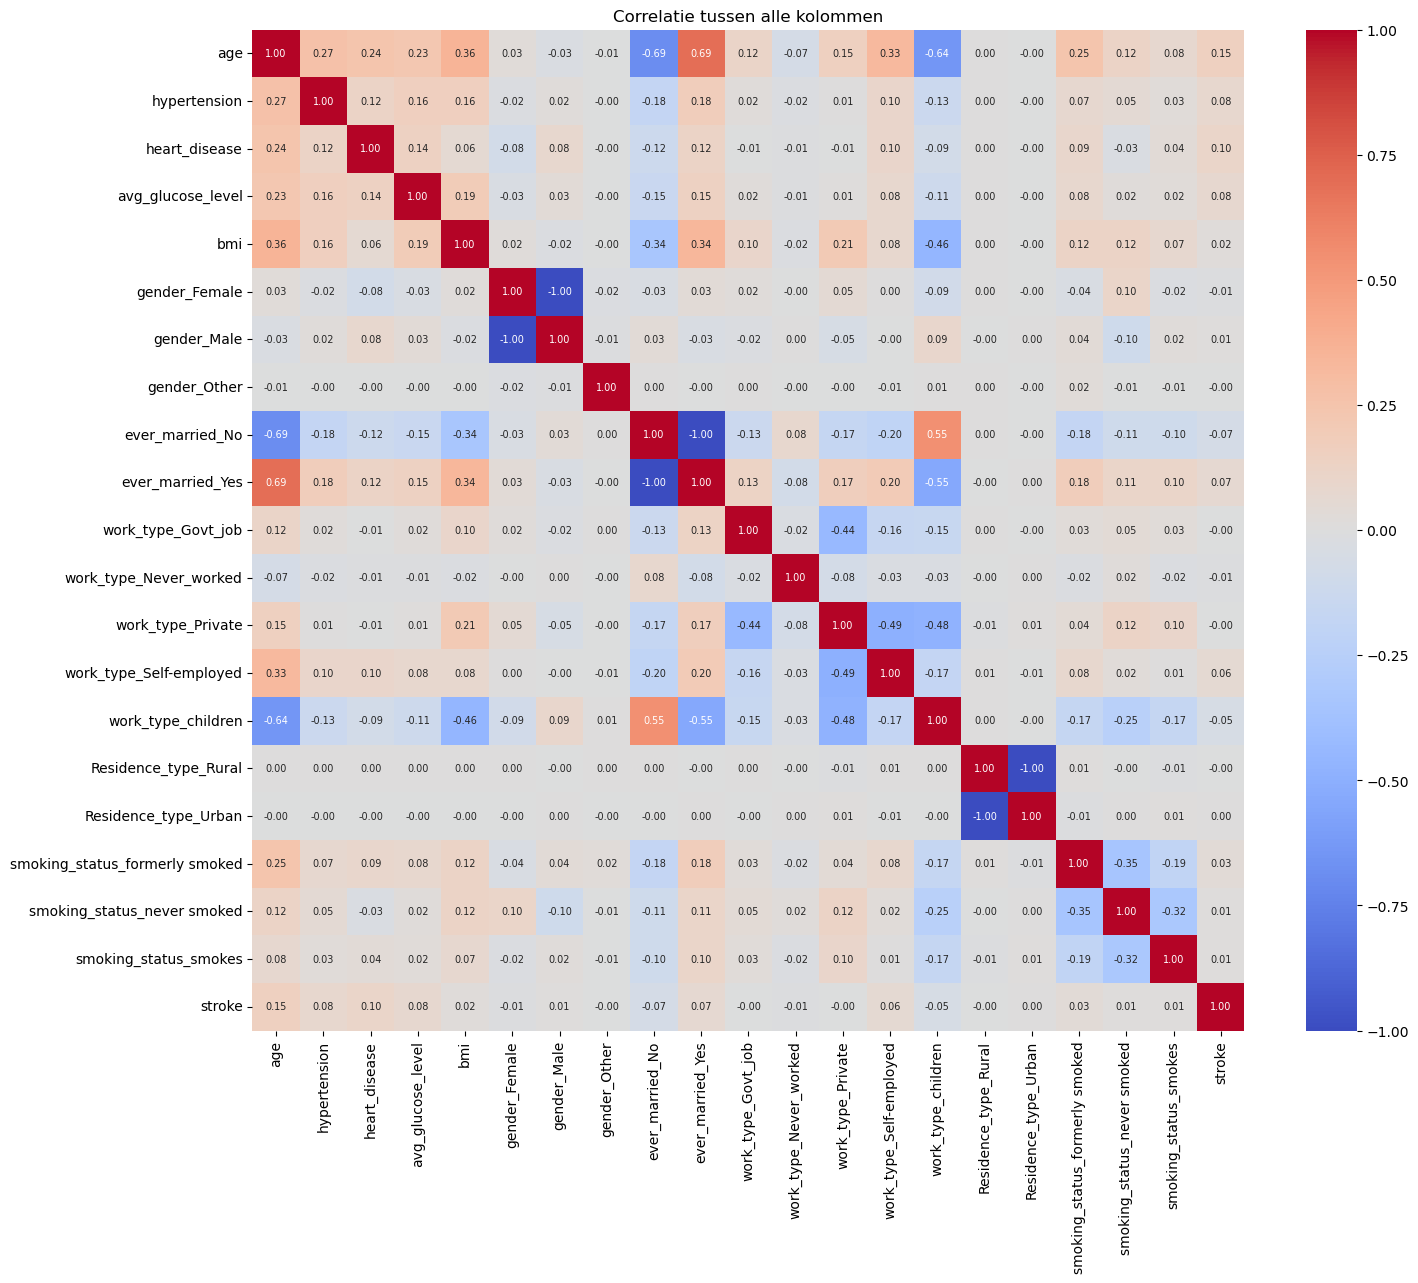

In [6]:
# importeren voor de grafieken

# id weglaten en True/False omzetten naar 1/0 zodat we kunnen rekenen
df_num = df.drop(columns=["id"]).astype(float)

# correlatiematrix: correlatie tussen alle kolommen
correlaties = df_num.corr()

# heatmap met de waarde in ieder vakje (2 decimalen)
plt.figure(figsize=(16, 13))
sns.heatmap(correlaties, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlatie tussen alle kolommen")
plt.show()

##### Toelichting
- **Relatie met stroke (onderste rij):** `age` heeft de sterkste correlatie met stroke (0,15), daarna `heart_disease` (0,10), `hypertension` (0,08) en `avg_glucose_level` (0,08). `bmi`, gender en woonplaats hebben bijna geen correlatie. Alle correlaties met stroke zijn klein; dat komt ook doordat stroke zo weinig voorkomt. Daarom bekijken we de variabelen hieronder ook nog apart.
- **Relaties tussen de onafhankelijke variabelen:** `age` hangt sterk samen met `ever_married_Yes` (0,69) en negatief met `work_type_children` (-0,64). Ouderen zijn vaker getrouwd en kinderen zijn jong. We kunnen aannemen dat als getrouwde mensen vaker stroke hebben, kan dat door hun leeftijd komen.
- **Dummykolommen:** paren als `gender_Female`/`gender_Male`, `ever_married_No`/`ever_married_Yes` en `Residence_type_Rural`/`Residence_type_Urban` hebben een correlatie van -1,00. Ze zijn elkaars tegenovergestelde en bevatten dus dezelfde informatie.

#### Stap 2: numerieke variabelen (boxplots)

Met een boxplot vergelijken we de verdeling van `age`, `avg_glucose_level` en `bmi` tussen patiënten zonder stroke (0) en met stroke (1). De streep in de doos is de mediaan; de doos bevat de middelste 50% van de patiënten.

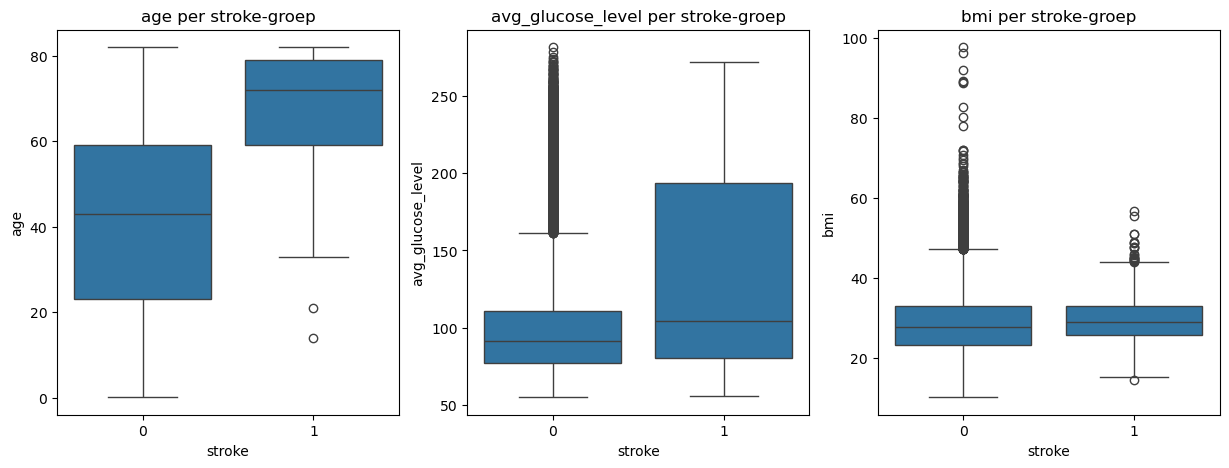

In [7]:
# drie boxplots naast elkaar: per variabele stroke 0 tegenover stroke 1
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, kolom in zip(axes, ["age", "avg_glucose_level", "bmi"]):
    sns.boxplot(data=df, x="stroke", y=kolom, ax=ax)
    ax.set_title(f"{kolom} per stroke-groep")
plt.show()

##### Toelichting
- **age**: patiënten met stroke zijn duidelijk ouder. De mediane leeftijd is ongeveer 72 jaar bij stroke en ongeveer 43 jaar zonder stroke.
- **avg_glucose_level**: bij stroke ligt de mediaan hoger (ongeveer 104 tegenover 91) en de doos loopt veel verder omhoog. Een deel van de stroke-patiënten heeft dus een hoog glucosegehalte.
- **bmi**: de boxen lijken erg op elkaar dus BMI hangt weinig samen met stroke. Er zijn wel uitschieters met een extreem hoge BMI (tot 97,6) voor geen stroke-patiënten.

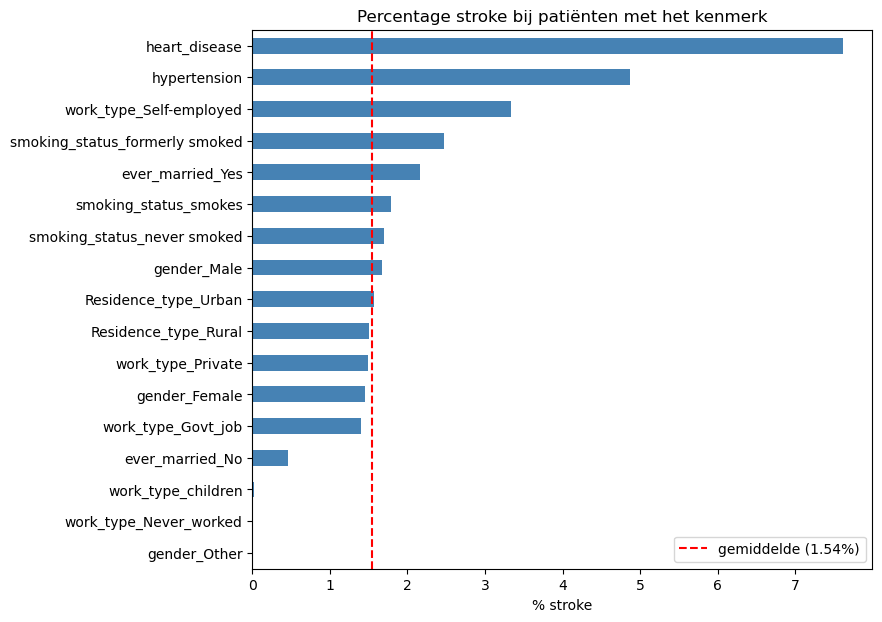

gender_Other                      0.00
work_type_Never_worked            0.00
work_type_children                0.02
ever_married_No                   0.45
work_type_Govt_job                1.40
gender_Female                     1.45
work_type_Private                 1.49
Residence_type_Rural              1.51
Residence_type_Urban              1.57
gender_Male                       1.67
smoking_status_never smoked       1.70
smoking_status_smokes             1.79
ever_married_Yes                  2.16
smoking_status_formerly smoked    2.47
work_type_Self-employed           3.34
hypertension                      4.87
heart_disease                     7.62
dtype: float64

In [8]:
# functie: percentage stroke bij patiënten waarbij de kolom 1 (True) is
def stroke_percentage(kolom):
    groep = df[df[kolom] == 1]
    return groep["stroke"].mean() * 100


# alle ja/nee-kolommen (alles behalve id, de numerieke kolommen en stroke)
ja_nee_kolommen = df.columns.drop(
    ["id", "age", "avg_glucose_level", "bmi", "stroke"])

# percentage per kolom berekenen en sorteren
percentages = pd.Series(
    {kolom: stroke_percentage(kolom) for kolom in ja_nee_kolommen}
).sort_values()

# gemiddelde percentage stroke in de hele dataset
gemiddelde = df["stroke"].mean() * 100

# staafgrafiek met het gemiddelde als stippellijn
percentages.plot(kind="barh", figsize=(8, 7), color="steelblue")
plt.axvline(gemiddelde, color="red", linestyle="--",
            label=f"gemiddelde ({gemiddelde:.2f}%)")
plt.title("Percentage stroke bij patiënten met het kenmerk")
plt.xlabel("% stroke")
plt.legend()
plt.show()

percentages.round(2)

##### Toelichting
- **heart_disease** (7,62%) en **hypertension** (4,87%) hebben het hoogste percentage stroke: veel hoger dan het gemiddelde van 1,54%.
- **work_type_Self-employed** (3,34%), **smoking_status_formerly smoked** (2,47%) en **ever_married_Yes** (2,16%) liggen ook boven het gemiddelde. Dit zijn vaak oudere mensen, dus dit komt waarschijnlijk voor een groot deel door de leeftijd.
- **work_type_children** (0,02%), **work_type_Never_worked** (0%) en **ever_married_No** (0,45%) liggen ver onder het gemiddelde; dit zijn vooral jonge mensen.
- **Residence_type** (Rural 1,51%, Urban 1,57%) en **gender** (vrouw 1,45%, man 1,67%) maken weinig verschil. `gender_Other` heeft 0% maar bestaat uit maar 6 patiënten, dus daar kunnen we niets over zeggen.

#### Stap 4: percentage stroke per leeftijdsgroep

Omdat leeftijd de sterkste relatie heeft, delen we de patiënten op in leeftijdsgroepen van 10 jaar en berekenen we per groep het percentage stroke.

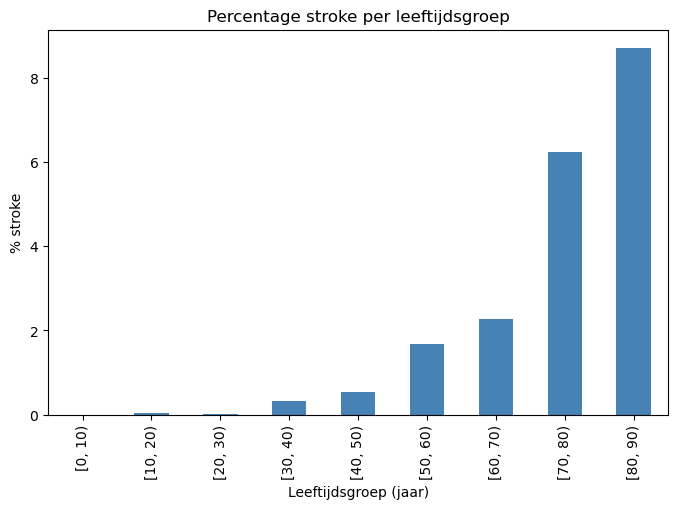

age
[0, 10)     0.00
[10, 20)    0.03
[20, 30)    0.02
[30, 40)    0.33
[40, 50)    0.55
[50, 60)    1.67
[60, 70)    2.28
[70, 80)    6.24
[80, 90)    8.71
Name: stroke, dtype: float64

In [9]:
# leeftijd opdelen in groepen van 10 jaar: [0, 10), [10, 20), ...
leeftijdsgroep = pd.cut(df["age"], bins=range(0, 100, 10), right=False)

# percentage stroke per leeftijdsgroep
per_groep = df.groupby(leeftijdsgroep, observed=True)["stroke"]
stroke_per_leeftijd = per_groep.mean() * 100

# staafgrafiek
stroke_per_leeftijd.plot(kind="bar", figsize=(8, 5), color="steelblue")
plt.title("Percentage stroke per leeftijdsgroep")
plt.xlabel("Leeftijdsgroep (jaar)")
plt.ylabel("% stroke")
plt.show()

stroke_per_leeftijd.round(2)

##### Toelichting
Onder de 30 jaar komt stroke bijna niet voor (0 tot 0,03%). Vanaf 50 jaar stijgt het percentage duidelijk: 1,67% (50–60), 2,28% (60–70), 6,24% (70–80) en 8,71% (80+). Hoe ouder, hoe groter de kans op stroke.

### 1.4.4 Belangrijkste bevindingen van de EDA
1. **De data is sterk ongebalanceerd.** Maar 1,54% van de patienten heeft een herseninfarct gehad. Een model dat altijd "geen stroke" voorspelt, heeft al ongeveer 98,5% accuracy, maar vindt geen enkele stroke-patiënt. Accuracy is dus geen goede maatstaf; we moeten letten op bijvoorbeeld recall en F1-score (Onder stap 2). 
2. **Leeftijd is de belangrijkste variabele.** Stroke komt onder de 30 bijna niet voor en stijgt naar 8,71% bij 80 jaar en ouder (Stap 4).
3. **Hartziekte en hypertensie hangen duidelijk samen met stroke** (7,62% en 4,87% tegenover gemiddeld 1,54%) (Onder stap 2).
4. **Een hoog glucosegehalte hangt samen met stroke.** Stroke-patienten hebben vaker een hoog glucosegehalte (Stap 2). 
5. **Sommige verbanden komen waarschijnlijk door leeftijd.** Getrouwde mensen, zelfstandigen en ex-rokers hebben vaker stroke, maar zijn ook gemiddeld ouder. Kinderen en mensen die nooit gewerkt hebben, hebben bijna nooit stroke omdat ze jong zijn (Onder stap 2).
6. **BMI, geslacht en woonplaats hebben weinig invloed** op stroke (Stap 1).
7. **Geen enkele variabele voorspelt stroke alleen goed.** Zelfs bij 80+ heeft ruim 91% geen stroke (Stap 4). Het model zal daarom meerdere variabelen samen moeten gebruiken en waarschijnlijk ook patienten onterecht als risico aanwijzen. In een medische context is dat minder erg dan een stroke-patient missen.

### 1.4.5 Data opschonen 

In [10]:
def datakwaliteit(df):
    """Geeft een overzicht van mogelijke datakwaliteitsproblemen in de dataset."""
    resultaten = {
        "ontbrekende waarden": df.isna().sum().sum(),
        "dubbele regels (alle kolommen)": df.duplicated().sum(),
        "dubbele patient-id's": df["id"].duplicated().sum(),
        "leeftijd < 0 of > 120": ((df["age"] < 0) | (df["age"] > 120)).sum(),
        "glucose <= 0": (df["avg_glucose_level"] <= 0).sum(),
        "bmi <= 0": (df["bmi"] <= 0).sum(),
    }
    return pd.Series(resultaten)


datakwaliteit(df)

ontbrekende waarden               0
dubbele regels (alle kolommen)    0
dubbele patient-id's              0
leeftijd < 0 of > 120             0
glucose <= 0                      0
bmi <= 0                          0
dtype: int64

##### Toelichting

Er zijn geen ontbrekende waarden, geen dubbele regels en geen dubbele patiënt-id's. Ook zijn er geen onmogelijke waarden voor leeftijd, glucose of BMI. Op basis van deze controles hoeven we dus geen regels te verwijderen wegens datakwaliteitsproblemen.

In [11]:
patient_ids = df["id"]
df_model = df.drop(columns=["id"])

# boolean-kolommen (True/False) zijn eigenlijk 0/1-categorieen: omzetten naar int
kolommen_bool = df_model.select_dtypes(include="bool").columns
df_model[kolommen_bool] = df_model[kolommen_bool].astype(int)

print(f"Aantal rijen: {df_model.shape[0]}")
print(f"Aantal kolommen (na verwijderen van id): {df_model.shape[1]}")
print(f"Aantal omgezette boolean-kolommen: {len(kolommen_bool)}")
print(df_model.dtypes.value_counts())

Aantal rijen: 33550
Aantal kolommen (na verwijderen van id): 21
Aantal omgezette boolean-kolommen: 15
int64      18
float64     3
Name: count, dtype: int64


### Bevindingen 

**1. De kolom `id`**

`id` is een uniek administratief nummer per patiënt en heeft geen medische of statistische relatie met stroke (dit hebben we in de correlatie-analyse in 1.4.3 ook niet gebruikt). Voor het trainen van een model voegt deze kolom dus geen voorspellende waarde toe en kan hij een model zelfs in de war brengen als hij per ongeluk als kenmerk wordt meegenomen. We verwijderen `id` daarom uit de data die we gebruiken om te modelleren, maar bewaren de id's apart, omdat we die van `test.csv` nodig hebben voor de Kaggle-inzending.

**2. `gender_Other` (6 patiënten)**

Deze groep bestaat uit 6 patiënten (0,02% van de dataset), van wie niemand stroke heeft gehad. We verwijderen deze rijen niet: het zijn geen foutieve waarden maar een geldige, zij het kleine, categorie. Het verwijderen van deze patiënten zou de toch al kleine stroke-groep (517 van de 33.550, oftewel 1,54%) verder verkleinen. We houden er wel rekening mee dat deze categorie te klein is om harde conclusies over te trekken. Bij cross-validation gebruiken we gestratificeerd splitsen op basis van stroke, zodat de verhouding tussen patiënten met en zonder stroke zo goed mogelijk behouden blijft in de verschillende folds. Stratificatie wordt hierbij dus toegepast op stroke en niet op gender_Other.

**3. Patiënten jonger dan 1 jaar (376 rijen, jongste patiënt 0,08 jaar ≈ 1 maand)**

De leeftijd van deze patiënten is ongebruikelijk, maar op basis van alleen de leeftijd kunnen we niet concluderen dat deze waarden foutief zijn. Omdat er geen duidelijke aanwijzing is dat deze rijen fouten in de dataset zijn, verwijderen we deze patiënten niet. We behouden de waarden zodat er geen mogelijk relevante observaties verloren gaan.


**4. Extreme BMI-waarde (max. 97,6)**

Deze waarde valt ver buiten de rest van de verdeling (75e percentiel ligt op 32,8), maar een BMI van 97,6 is medisch gezien - zij het zeer zeldzaam - mogelijk, en we hebben geen aanwijzing dat het om een fout gaat (bijvoorbeeld een verkeerd ingevoerde eenheid). Omdat we sowieso al weinig stroke-patiënten hebben, verwijderen we liever geen rijen op basis van een vermoeden. Modellen die gevoelig zijn voor uitschieters (zoals KNN of SVM) houden we hier bij standaardisatie (1.6) rekening mee.

### 1.4.6 Standaardiseren



Standaardiseren van data, ook wel z-score normalisatie genoemd, is een voorbewerkingstechniek waarbij elke waarde van een numerieke kolom wordt herschaald volgens de formule

$$z = \frac{x - \mu}{\sigma}$$

waarbij $\mu$ het gemiddelde en $\sigma$ de standaarddeviatie van die kolom is (scikit-learn developers, z.d.-a). Na deze transformatie heeft de kolom een gemiddelde van 0 en een standaarddeviatie van 1, waardoor alle gestandaardiseerde kolommen dezelfde schaal krijgen. De onderlinge verhoudingen tussen de waarden, en dus de vorm van de verdeling, blijven daarbij hetzelfde: alleen de schaal verandert, niet de informatie in de data.

Standaardisatie is met name gewenst bij algoritmes die gevoelig zijn voor de schaal van de invoerkenmerken, omdat zij rekenen met afstanden of met gradients (Géron, 2019; scikit-learn developers, z.d.-a). Bij KNN wordt bijvoorbeeld de (euclidische) afstand tussen patiënten berekend om de dichtstbijzijnde buren te bepalen; zonder standaardisatie domineert een kenmerk met een groot bereik, zoals `avg_glucose_level` (55-282), automatisch de afstand ten opzichte van een kenmerk met een kleiner bereik, zoals `age` (0-82), ook wanneer dat laatste kenmerk inhoudelijk net zo belangrijk of belangrijker is (scikit-learn developers, z.d.-b). Logistic Regression wordt getraind met gradient descent, een iteratief optimalisatieproces dat trager en instabieler convergeert wanneer kenmerken sterk verschillende schalen hebben, omdat kenmerken met grote waarden tot grotere gradients leiden (Géron, 2019). Ook SVM is gevoelig voor schaal, omdat dit model de scheidingslijn zoekt met de grootste marge tussen klassen, wat eveneens op afstanden is gebaseerd; een kenmerk met een grote schaal kan daardoor ten onrechte de gevonden scheidingslijn domineren (scikit-learn developers, z.d.-a). Boomgebaseerde modellen zoals Decision Tree, Random Forest, Gradient Boosting en XGBoost zijn daarentegen volledig invariant voor het schalen van kenmerken: zij splitsen per kenmerk op basis van een drempelwaarde, en de volgorde van de waarden - en daarmee de gevonden splitsingen - verandert niet door standaardisatie (Müller & Guido, 2016). Voor deze modellen is standaardisatie dus niet nodig, al is het ook niet schadelijk.

Voor deze dataset voegt standaardisatie waarde toe, specifiek voor de drie continue numerieke kenmerken `age`, `avg_glucose_level` en `bmi`. Zoals te zien was in de basisstatistieken in 1.4.2, hebben deze kenmerken duidelijk verschillende schalen: `age` loopt van 0 tot 82, `avg_glucose_level` van 55 tot ruim 280 en `bmi` van 10 tot bijna 98. Zonder standaardisatie zou `avg_glucose_level` dus een onevenredig grote invloed krijgen bij afstandsgebaseerde modellen zoals KNN en SVM, en zou Logistic Regression trager convergeren - wat we ook daadwerkelijk zagen, want ons Logistic Regression-model gaf hierboven zonder standaardisatie een `ConvergenceWarning`. 

Een ConvergenceWarning betekent dat het model binnen het ingestelde aantal iteraties nog geen optimale oplossing had gevonden. Dit betekent niet automatisch dat het model fout is, maar het geeft aan dat het trainingsproces niet volledig tot een oplossing is gekomen. Een mogelijke oorzaak is dat de kenmerken sterk verschillende schalen hebben. Door de continue kenmerken te standaardiseren, brengen we ze naar een vergelijkbare schaal, waardoor het optimalisatieproces makkelijker kan verlopen.

De overige kolommen (`hypertension`, `heart_disease` en alle one-hot encoded kolommen, zoals `gender_Male` of `smoking_status_smokes`) standaardiseren we bewust niet: dit zijn al 0/1-indicatoren met een vergelijkbare en betekenisvolle schaal, en standaardiseren zou ze alleen minder interpreteerbaar maken zonder dat dit enig voordeel oplevert.

We voeren de standaardisatie daarom uit met de `StandardScaler` van Scikit-learn, toegepast op alleen deze drie kolommen, en slaan het resultaat op in een losse kopie (`df_gestandaardiseerd`), zodat de oorspronkelijke, ongestandaardiseerde data (`df_model`) beschikbaar blijft voor de boomgebaseerde modellen. Hieronder passen we de standaardisatie toe op de volledige dataset, enkel om het effect te illustreren; bij het daadwerkelijke trainen van modellen in Opdracht 3 herhalen we dit per cross-validation-fold (bijvoorbeeld met een Scikit-learn `Pipeline`), zodat de scaler alleen wordt gefit op trainingsdata en we geen data leakage veroorzaken naar de validatie- of testdata.

### Bronnen 

Géron, A. (2019). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (2e druk). O'Reilly Media.

Müller, A. C., & Guido, S. (2016). *Introduction to machine learning with Python: A guide for data scientists*. O'Reilly Media.

scikit-learn developers. (z.d.-a). *6.3. Preprocessing data*. In *scikit-learn: Machine learning in Python*. Geraadpleegd 30 september 2026, van https://scikit-learn.org/stable/modules/preprocessing.html

scikit-learn developers. (z.d.-b). *Importance of feature scaling*. In *scikit-learn: Machine learning in Python*. Geraadpleegd 30 september 2026, van https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html


In [12]:
# kopie van de opgeschoonde dataset
df_gestandaardiseerd = df_model.copy()

# Kolommen die we gaan standaardiseren
kolommen_standaardiseren = [
    "age",
    "avg_glucose_level",
    "bmi"
]

# StandardScaler aanmaken
scaler = StandardScaler()

# Alleen de drie continue variabelen standaardiseren
df_gestandaardiseerd[kolommen_standaardiseren] = scaler.fit_transform(
    df_gestandaardiseerd[kolommen_standaardiseren]
)


df_gestandaardiseerd.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,-0.525660,0,0,-0.949208,0.603791,0,1,0,1,0,...,0,1,0,0,1,0,0,0,1,0
1,1.476378,1,0,2.648741,2.492734,1,0,0,0,1,...,0,0,1,0,1,0,0,1,0,0
2,-1.193007,0,0,0.750898,-1.233751,0,1,0,1,0,...,0,1,0,0,1,0,0,1,0,0
3,0.230665,0,0,-0.918587,-0.051556,0,1,0,0,1,...,0,0,1,0,0,1,0,1,0,0
4,0.319645,0,0,2.818942,0.025544,0,1,0,0,1,...,0,0,1,0,1,0,1,0,0,0


## Opdracht 2. Evaluatie

### 2.1 Metrics

In dit hoofdstuk wordt onderzocht hoe goed een Machine Learning-model presteert. Eerst bekijken we welke metrics geschikt zijn voor dit classificatieprobleem. Daarna leggen we uit hoe deze metrics worden berekend aan de hand van een confusion matrix en tonen we de resultaten van een gekozen Machine Learning-algoritme. Tot slot bespreken we waarom in de Kaggle-competitie de F1-score wordt gebruikt en waarom deze maatstaf geschikt is voor het voorspellen van een stroke.

Stroke-voorspelling is een vorm van binaire classificatie: elke patiënt wordt ingedeeld in één van twee klassen (wel of geen stroke). Om te bepalen hoe goed een model hierin presteert, wordt doorgaans gebruikgemaakt van metrics die zijn afgeleid uit de confusion matrix: Accuracy, Precision, Recall, F1-score en ROC-AUC (scikit-learn developers, z.d.-c). Accuracy geeft het aandeel van alle voorspellingen dat correct is. Precision geeft aan welk deel van de patiënten die het model als 'stroke' voorspelt, daadwerkelijk stroke heeft. Recall (ook wel sensitiviteit) geeft aan welk deel van de patiënten die daadwerkelijk stroke hebben, door het model ook als zodanig wordt herkend. F1-score is het harmonisch gemiddelde van Precision en Recall en vat beide in één getal samen. ROC-AUC, ten slotte, geeft aan hoe goed het model in staat is om, over alle mogelijke drempelwaarden heen, stroke-patiënten te onderscheiden van patiënten zonder stroke.

Bij een sterk ongebalanceerde dataset zoals deze (slechts 1,54% van de patiënten heeft stroke gehad, zie 1.4.1) is Accuracy echter een misleidende maatstaf: een model dat voor elke patiënt simpelweg 'geen stroke' voorspelt, behaalt al bijna 98,5% accuracy zonder ook maar één stroke-patiënt te herkennen (He & Garcia, 2009). Precision, Recall en F1-score geven in dat geval een veel eerlijker beeld van de daadwerkelijke prestaties van een model op de kleine groep patiënten waar het eigenlijk om draait. We tonen dit hieronder concreet aan de hand van Logistic Regression. Deze keuze is beargumenteerd, niet willekeurig. 

Ten eerste sluit het aan op het werk in 1.6: we hebben de data daar al gestandaardiseerd en specifiek beargumenteerd dat juist Logistic Regression (in tegenstelling tot boomgebaseerde modellen) baat heeft bij standaardisatie, dus dit model laat dat effect direct zien. 

Ten tweede is Logistic Regression in de medische literatuur de standaard-benchmark voor klinische risicovoorspelling bij binaire uitkomsten zoals stroke; een systematische review van 71 vergelijkende studies vond geen bewijs dat complexere machine-learning-modellen beter presteren dan Logistic Regression voor dit type klinische voorspelproblemen (Christodoulou et al., 2019). 

Ten derde is het model goed interpreteerbaar: de coëfficiënten zijn direct te vertalen naar odds ratios per risicofactor, wat in een medische context belangrijk is om aan artsen te kunnen uitleggen welke factoren het risico verhogen (Hosmer et al., 2013) - relevant voor het advies dat we in Opdracht 4 moeten geven. 

Ten slotte geeft `predict_proba` direct bruikbare kansen, nodig voor de ROC-AUC, terwijl een model als SVM dat zonder extra kalibratie niet standaard doet. 

In [13]:
def bereken_metrics(y_waar, y_voorspeld, y_kans=None):
    """Berekent de belangrijkste classificatiemetrics voor een model."""
    resultaten = {
        "Accuracy": accuracy_score(y_waar, y_voorspeld),
        "Precision": precision_score(y_waar, y_voorspeld, zero_division=0),
        "Recall": recall_score(y_waar, y_voorspeld, zero_division=0),
        "F1-score": f1_score(y_waar, y_voorspeld, zero_division=0),
    }
    if y_kans is not None:
        resultaten["ROC-AUC"] = roc_auc_score(y_waar, y_kans)
    return pd.Series(resultaten).round(3)


# train/test-split, gestratificeerd vanwege de ongebalanceerde data
X = df_gestandaardiseerd.drop(columns=["stroke"])
y = df_gestandaardiseerd["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_kans = model.predict_proba(X_test)[:, 1]

print(bereken_metrics(y_test, y_pred, y_kans))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy     0.985
Precision    0.000
Recall       0.000
F1-score     0.000
ROC-AUC      0.854
dtype: float64

Confusion matrix:
[[6607    0]
 [ 103    0]]


Dit resultaat laat precies zien waarom Accuracy hier misleidend is: het model behaalt een Accuracy van 0,985, wat op het eerste gezicht uitstekend lijkt. De confusion matrix laat echter zien dat het model alle 103 stroke-patiënten in de testset mist (0 echt-positieven) en iedereen als 'geen stroke' voorspelt. Precision, Recall en F1-score zijn daardoor allemaal 0. De ROC-AUC van 0,854 laat zien dat het model, over verschillende drempelwaarden heen, wel degelijk onderscheidend vermogen heeft tussen patiënten met en zonder stroke; met de standaard drempelwaarde van 0,5 kiest het model echter nooit voor de (kleine) stroke-klasse. 

### 2.2 Berekening van de metrics met een confusion matrix


Alle metrics uit 2.1 worden berekend met de getallen uit een confusion matrix. Een confusion matrix laat zien hoeveel voorspellingen van het model goed en fout zijn. De rijen zijn de echte klasse en de kolommen de voorspelde klasse. Bij ons is stroke (1) de positieve klasse, omdat we juist de patienten met een stroke willen vinden (Géron, 2019).

| | Voorspeld: geen stroke (0) | Voorspeld: stroke (1) |
|---|---|---|
| **Echt: geen stroke (0)** | True Negative (TN) | False Positive (FP) |
| **Echt: stroke (1)** | False Negative (FN) | True Positive (TP) |

- **TN (True Negative):** de patient heeft geen stroke en het model voorspelt ook geen stroke. Dit is goed.
- **FP (False Positive):** de patient heeft geen stroke, maar het model voorspelt wel een stroke. Dit is een vals alarm.
- **FN (False Negative):** de patient heeft wel een stroke, maar het model voorspelt geen stroke. De patiënt wordt dus gemist. Bij een medische toepassing is dit de ergste fout.
- **TP (True Positive):** de patient heeft een stroke en het model voorspelt dat ook. Dit is goed.


Refrentie van tabel: https://chatgpt.com/c/6ac3e564-085c-83ed-a871-d5dd2dbc2757

### 2.2.1 Confusion matrix van ons model

Wij maken de confusion matrix van het Logistic Regression model uit 2.1. Met `ravel()` halen we de vier getallen uit de matrix zodat we er daarna zelf mee kunnen rekenen. Omdat we de confusion matrix vaker gaan tekenen, zetten we dat in een functie.

True Negatives: 6607, False Positives: 0, False Negatives: 103, True Positives: 0


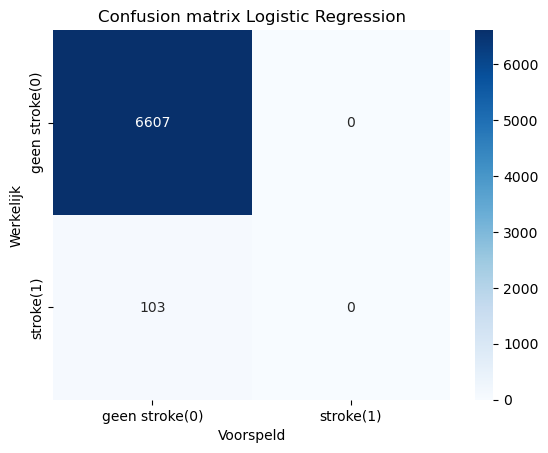

In [14]:
def confusion_matrix_heatmap(cm, titel):
    """deze functie maakt confusion matrix als heatmap met de aantallen erin"""
    labels = ["geen stroke(0)", "stroke(1)"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels) # we kiezen blauwe kleur om onze visualisatie duidelijker aan te tonen.
    plt.xlabel("Voorspeld")
    plt.ylabel("Werkelijk")
    plt.title(titel)
    plt.show()

# hier confusion matrix van 2.1 laten zien
cm = confusion_matrix(y_test, y_pred)

# die vier getallen uit matrix halen en de volgorde gaat zo : (TN, FP, FN, TP)
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives: {tn}, False Positives: {fp}, False Negatives: {fn}, True Positives: {tp}")

confusion_matrix_heatmap(cm, "Confusion matrix Logistic Regression")

In de testset zitten 6710 patienten, waarvan 103 met een stroke. Het model voorspelt bij niemand een stroke: TP en FP zijn allebei 0. Alle 103 stroke-patienten worden dus gemist (FN = 103) en dit komt doordat stroke zo weinig voorkomt. Het model voorspelt een patient pas als stroke als de kans hoger is dan 0,5 en dat gebeurt bij geen enkele patient en dit tonen we straks in deze notebook.

### 2.2.2 Hoe wordt iedere metric berekend?


Hieronder staat per metric wat hij meet, de formule en de berekening met de getallen van ons model.

**Accuracy** is het deel van alle voorspellingen dat goed is.

$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$

Ons model: (0 + 6607) / 6710 = 0,985.

**Precision** geeft aan welk deel van de patienten die het model als stroke voorspelt ook echt een stroke heeft. Het zegt dus hoe betrouwbaar een stroke voorspelling is.

$$\text{Precision} = \frac{TP}{TP + FP}$$

Ons model: 0 / (0 + 0). Delen door 0 kan niet, omdat het model niemand als stroke voorspelt. In `bereken_metrics` hebben we `zero_division=0` ingesteld, daarom geeft scikit-learn in dit geval 0.

**Recall** geeft aan welk deel van de patiënten die echt een stroke hebben, door het model wordt gevonden.

$$\text{Recall} = \frac{TP}{TP + FN}$$

Ons model: 0 / (0 + 103) = 0. Het model vindt geen enkele stroke-patient.

**F1-score** is het harmonisch gemiddelde van precision en recall. De F1-score is alleen hoog als precision en recall allebei hoog zijn.

$$F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

Ons model: precision en recall zijn allebei 0, dus de F1-score is ook 0.

**ROC-AUC** werkt anders. Deze metric gebruikt niet een confusion matrix maar de kansen die het model geeft. Dit leggen we uit in 2.2.4.

Om te controleren of we de formules goed begrijpen, hebben we ze zelf in een functie gezet en vergelijken we de uitkomst met `bereken_metrics` uit 2.1.


Refrentie van formules markdown stijl: https://chatgpt.com/share/6ac3ea77-0a20-83ed-b2c0-808dc53e5a97

In [15]:
def metrics_met_de_hand(tn, fp, fn, tp):
    """Rekent de metrics uit met de getallen van de confusion matrix."""
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    # voorspelt het model niemand als stroke, dan is tp + fp gelijk
    # aan 0 en kunnen we niet delen: dan wordt precision 0
    if tp + fp == 0:
        precision = 0
    else:
        precision = tp / (tp + fp)

    recall = tp / (tp + fn)

    # F1 kan ook niet als precision en recall allebei 0 zijn
    if precision + recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)

    return pd.Series({"Accuracy": accuracy, "Precision": precision,
                      "Recall": recall, "F1-score": f1}).round(3)


# zelf uitgerekend naast de uitkomst van scikit-learn
vergelijking = pd.DataFrame({
    "Met de hand": metrics_met_de_hand(tn, fp, fn, tp),
    "Scikit-learn": bereken_metrics(y_test, y_pred),
})
vergelijking

,Met de hand,Scikit-learn
Accuracy,0.985,0.985
Precision,0.000,0.000
Recall,0.000,0.000
F1-score,0.000,0.000


Uit onze onderzoek naar uitkomsten van Scikit-learn en "metdehand" functie hebben we waargenomen dat de uitkomsten hetzelfde zijn dus de formules kloppen. Je ziet ook goed waarom accuracy hier een slechte maatstaf is: de accuracy is 0,985, terwijl het model geen enkele stroke-patient vindt. Van de patienten in de testset heeft 98,5% geen stroke, dus als je altijd 'geen stroke' voorspelt heb je al bijna alles goed.

### 2.2.3 Een voorbeeld met een lagere drempel

Omdat ons model bij niemand een stroke voorspelt, zijn precision, recall en F1-score allemaal 0 en daardoor zie je nog niet goed hoe deze formules werken. Logistic Regression geeft voor iedere patient een kans op stroke (`predict_proba`). Standaard wordt een patient als stroke voorspeld als die kans hoger is dan 0,5 (dit heet de drempel of threshold). We kijken eerst wat de hoogste kans is die het model geeft en daarna verlagen we de drempel als voorbeeld naar 0,1: een patient wordt dan als stroke voorspeld als de kans 10% of hoger is.

Voor duidelijkheid, dit doen we alleen om de metrics beter uit te leggen. Het kiezen van een goede drempel en oplossen van de ongebalanceerde data komen later in het portfolio aan bod.

Hoogste kans op stroke: 0.27
TN: 6486  FP: 121  FN: 93  TP: 10


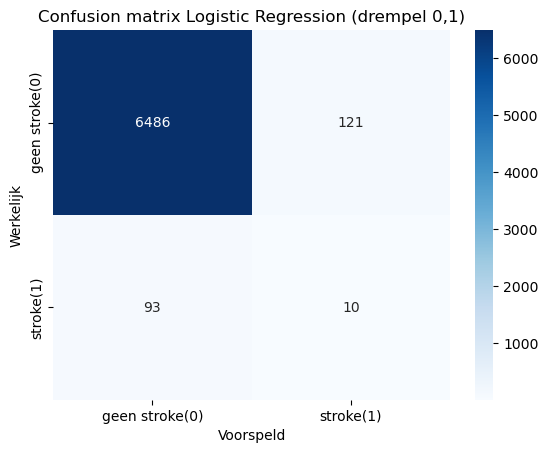

,Met de hand,Scikit-learn
Accuracy,0.968,0.968
Precision,0.076,0.076
Recall,0.097,0.097
F1-score,0.085,0.085


In [16]:
# hoogste kans op stroke die het model aan een patient geeft
print("Hoogste kans op stroke:", round(y_kans.max(), 3))

# drempel verlagen van 0,5 naar 0,1
y_pred_drempel = (y_kans >= 0.1).astype(int)

# nieuwe confusion matrix en de vier getallen
cm_drempel = confusion_matrix(y_test, y_pred_drempel)
tn2, fp2, fn2, tp2 = cm_drempel.ravel()
print("TN:", tn2, " FP:", fp2, " FN:", fn2, " TP:", tp2)

confusion_matrix_heatmap(cm_drempel,
                       "Confusion matrix Logistic Regression (drempel 0,1)")

# weer zelf uitgerekend naast scikit-learn
vergelijking_drempel = pd.DataFrame({
    "Met de hand": metrics_met_de_hand(tn2, fp2, fn2, tp2),
    "Scikit-learn": bereken_metrics(y_test, y_pred_drempel),
})
vergelijking_drempel

De hoogste kans die het model geeft is 0,27. Bij een drempel van 0,5 wordt dus niemand als stroke voorspeld. Met een drempel van 0,1 vullen we de formules in met de nieuwe confusion matrix:

- Accuracy = (10 + 6486) / 6710 = 0,968
- Precision = 10 / (10 + 121) = 0,076
- Recall = 10 / (10 + 93) = 0,097
- F1-score = 2 · 0,076 · 0,097 / (0,076 + 0,097) = 0,085

Het model vindt nu 10 van de 103 stroke-patienten. Daar staan wel 121 vals alarmen tegenover: van de 131 patienten die als stroke worden voorspeld, heeft maar 7,6% echt een stroke. De accuracy is gedaald van 0,985 naar 0,968 terwijl het model nu wel stroke-patienten vindt. Een hogere accuracy betekent hier dus niet dat het model beter is.

Ook zie je dat precision en recall tegen elkaar in werken: als je de drempel verlaagt, vind je meer stroke-patienten, maar krijg je ook meer vals alarmen.

### 2.2.4 ROC-AUC


De ROC-AUC kun je niet uit een confusion matrix halen, omdat deze metric naar alle mogelijke drempels tegelijk kijkt. Voor iedere drempel maak je een confusion matrix en bereken je twee getallen:

- **True Positive Rate (TPR)**: dit is hetzelfde als de recall: $TPR = \frac{TP}{TP + FN}$
- **False Positive Rate (FPR)**: het deel van de patiënten zonder stroke dat onterecht als stroke wordt voorspeld: $FPR = \frac{FP}{FP + TN}$

Als je voor alle drempels de FPR (x-as) tegen de TPR (y-as) zet, krijg je de ROC-curve. De ROC-AUC (Area Under the Curve) is de oppervlakte onder deze curve. Een perfect model heeft een AUC van 1 en een model dat gokt een AUC van 0,5. Dat is de diagonale lijn (Géron, 2019).

Hieronder rekenen we de TPR en FPR zelf uit voor drempels van 0 tot 1 in stappen van 0,001. Onze twee confusion matrices (drempel 0,5 en 0,1) zijn twee punten op deze curve.

Drempel 0,5: FPR = 0.0  TPR = 0.0
Drempel 0,1: FPR = 0.018  TPR = 0.097


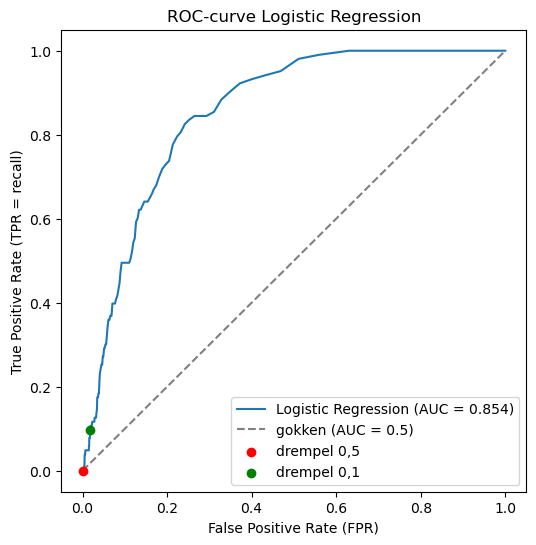

In [17]:
# drempels van 0 tot 1 in stappen van 0,001
drempels = [i / 1000 for i in range(1001)]
tpr_lijst = []
fpr_lijst = []

# per drempel een confusion matrix maken en TPR en FPR uitrekenen
for drempel in drempels:
    voorspelling = (y_kans >= drempel).astype(int)
    tn_d, fp_d, fn_d, tp_d = confusion_matrix(y_test, voorspelling).ravel()
    tpr_lijst.append(tp_d / (tp_d + fn_d))
    fpr_lijst.append(fp_d / (fp_d + tn_d))

# de twee punten van onze confusion matrices
print("Drempel 0,5: FPR =", round(fp / (fp + tn), 3),
      " TPR =", round(tp / (tp + fn), 3))
print("Drempel 0,1: FPR =", round(fp2 / (fp2 + tn2), 3),
      " TPR =", round(tp2 / (tp2 + fn2), 3))

# ROC curve tekenen, met de diagonaal (gokken) als vergelijking
auc = roc_auc_score(y_test, y_kans)
plt.figure(figsize=(6, 6))
plt.plot(fpr_lijst, tpr_lijst, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey",
         label="gokken (AUC = 0.5)")
plt.scatter(fp / (fp + tn), tp / (tp + fn), color="red", zorder=3,
            label="drempel 0,5")
plt.scatter(fp2 / (fp2 + tn2), tp2 / (tp2 + fn2), color="green", zorder=3,
            label="drempel 0,1")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR = recall)")
plt.title("ROC-curve Logistic Regression")
plt.legend()
plt.show()

Refrentie van code: https://chatgpt.com/share/6ac417b9-2e90-83eb-aab0-6b4dfa55a3e3

Oke dus bij drempel 0,5 zitten we linksonder in de hoek (FPR = 0 en TPR = 0), omdat het model niemand als stroke voorspelt en bij drempel 0,1 is de FPR 0,018 en de TPR 0,097. Hoe lager de drempel, hoe verder je over de curve naar rechtsboven gaat. Bij drempel 0 wordt iedereen als stroke voorspelt en zit je rechtsboven: de recall is dan 1, maar alle patienten zonder stroke zijn een vals alarm.

De ROC-AUC van ons model is 0,854 en je kunt dit lezen als de kans dat een willekeurige stroke-patient een hogere voorspelde kans krijgt dan een willekeurige patient zonder stroke. Het model heeft dus wel iets geleerd: stroke-patienten krijgen meestal een hogere kans. Het probleem zit vooral in de drempel van 0,5, die voor deze ongebalanceerde data veel te hoog is.

We moeten wel oppassen met de ROC-AUC bij ongebalanceerde data. De FPR wordt gedeeld door het grote aantal patienten zonder stroke (6.607) en daardoor geven 121 vals alarmen maar een FPR van 0,018 en ziet de curve er gunstig uit. Volgens Geron (2019) kun je bij een zeldzame positieve klasse daarom beter ook naar precision en recall kijken.

Refrentie Geron 2019: https://www.scirp.org/reference/referencespapers?referenceid=3265407

### 2.2.5 Overzicht

| Metric | Formule | Drempel 0,5 | Drempel 0,1 | Wat zegt het bij stroke? |
|---|---|---|---|---|
| Accuracy | (TP + TN) / (TP + TN + FP + FN) | 0,985 | 0,968 | Deel van alle voorspellingen dat goed is. Misleidend bij ongebalanceerde data. |
| Precision | TP / (TP + FP) | 0 | 0,076 | Hoe vaak een stroke voorspelling klopt. Laag betekent veel vals alarm. |
| Recall | TP / (TP + FN) | 0 | 0,097 | Welk deel van de stroke-patienten wordt gevonden. Laag betekent veel gemiste patienten. |
| F1-score | 2 · precision · recall / (precision + recall) | 0 | 0,085 | Combinatie van precision en recall. |
| ROC-AUC | Oppervlakte onder ROC-curve (TPR tegen FPR) | 0,854 | 0,854 | Hoe goed het model stroke en niet stroke-patienten uit elkaar houdt los van de drempel. |

Voor het voorspellen van een stroke is de recall belangrijk, omdat een gemiste stroke-patient (FN) de ergste fout is. Alleen naar recall kijken is wel te makkelijk: als je iedereen als stroke voorspelt is de recall 1, maar dan heb je niks aan het model. Daarom is de F1-score, die precision en recall combineert voor deze dataset een betere maatstaf dan accuracy.

## Opdracht 2.3 
Om te verklaren waarom de f1-score de beste maatstaf is voor dit vraagstuk, moeten wij eerst vaststellen wat de f1-score is. De f1-score is een maatstaf die precision en recall combineert, waarbij de uitkomst altijd tussen 0 en 1 ligt. De formule voor de f1-score ziet er als volgt uit:


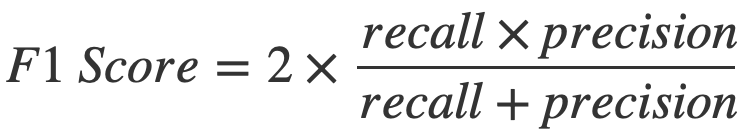

Zoals besproken in opdracht 2.1 geeft precision, in de context van dit onderzoek, aan welk deel van de patiënten die het model als 'stroke' voorspelt daadwerkelijk een stroke heeft gehad. Recall geeft aan welk deel van de patiënten die daadwerkelijk een stroke hebben gehad, ook als zodanig door het model wordt herkend. De f1-score is het harmonisch gemiddelde van deze twee metrics en is dus alleen hoog als beide hoog zijn. Een ander kenmerk van de f1-score is dat deze bruikbaar is bij sterk ongebalanceerde datasets.

Dat laatste is voor ons relevant, omdat onze dataset sterk ongebalanceerd is. Uit opdracht 1.4.1 bleek dat slechts 1,54% van alle patiënten in onze dataset daadwerkelijk een stroke heeft gehad: van de 33.550 patiënten zijn dat er ongeveer 517. Bij ongebalanceerde data geeft de accuracy een vertekend beeld. Een model dat voor iedere patiënt voorspelt dat er geen stroke komt, haalt namelijk al een accuracy van ongeveer 98,5%, terwijl het geen enkele stroke-patiënt herkent. Dat is precies wat ons model deed. In opdracht 2.1 kwam de accuracy uit op 0,985, wat op het eerste gezicht een uitstekend resultaat lijkt. Uit ons onderzoek bleek echter dat alle 103 stroke-patiënten in onze testset door het model als 'geen stroke' werden voorspeld (false negatives). Hierdoor waren de precision en recall beide 0, en dus ook de f1-score. De accuracy zei dus niets over de bruikbaarheid van het model.

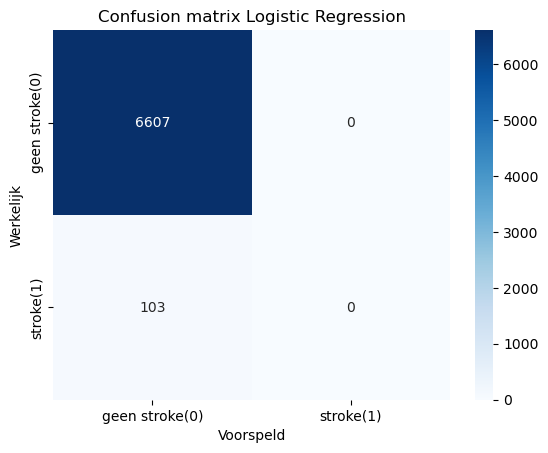 threshold/ drempel veranderen -> 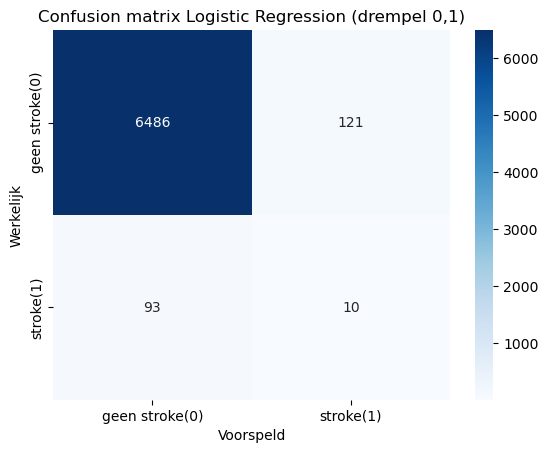

Ook precision of recall afzonderlijk zijn niet voldoende, omdat ze eenvoudig te beïnvloeden zijn. Een model dat iedere patiënt als 'stroke' voorspelt, haalt een recall van 1, maar is in de praktijk waardeloos. Een model dat slechts één patiënt als 'stroke' voorspelt en daar gelijk in heeft, haalt een precision van 1, maar mist bijna alle andere stroke-patiënten. Beide maatstaven moeten dus tegelijk goed zijn, en dat is precies wat de f1-score meet.

Daarnaast hebben in een medische context beide fouten reële gevolgen. Een gemiste stroke (false negative) is de ernstigste fout: de patiënt krijgt geen preventieve zorg of monitoring, terwijl een stroke kan leiden tot blijvende schade of overlijden. Een valse alarmering (false positive) is minder ernstig, maar niet zonder gevolgen: de patiënt ondergaat onnodig vervolgonderzoek of behandeling, wat leidt tot extra kosten, een grotere belasting van de zorg en onnodige onrust bij de patiënt. Wij willen dus geen model dat stroke-patiënten mist (recall), maar ook geen model dat te vaak ten onrechte voorspelt dat een patiënt een stroke zal krijgen (precision). De f1-score houdt met beide rekening, waardoor een model niet goed kan scoren door één van de twee fouten te negeren.

Dit zien wij ook terug in onze resultaten. Nadat wij in opdracht 2.2.3 de threshold van ons model aanpasten naar 0,1, wist het model 10 stroke-patiënten correct te voorspellen. De accuracy daalde daardoor van 0,985 naar 0,968, maar de f1-score steeg van 0 naar 0,085. De f1-score laat dus wel zien dat het model iets is gaan leren, terwijl de accuracy juist een verslechtering suggereert. De f1-score vormt echter een goed uitgangspunt, omdat deze beide fouten meeneemt. Dit is de reden waarom wij in dit vraagstuk kijken naar de f1-score en niet alleen naar de accuracy, precision of recall.